This notebook will be used to evaluate the fastSAM model (https://docs.ultralytics.com/fr/models/fast-sam) that will be used to segment images. From what it is said in their documentation, fastSAM is a lightweight and efficient model designed for real-time image segmentation tasks. It leverages advanced deep learning techniques to provide accurate segmentation results while maintaining high performance.

It will be evaluated to see if it corresponds to our needs and requirements. 

In [1]:
# imports
import os
import time
from pathlib import Path

import matplotlib.pyplot as plt
from ultralytics import ASSETS, FastSAM

In [11]:
img_folder = "data/fastSAM"
models_folder = "../models"

model_s = models_folder + "/FastSAM-s.pt"
model_x = models_folder + "/FastSAM-x.pt"

# get model 
model = FastSAM(str(model_x))  # or model_x

In [3]:
# show information about the model (layers, parameters, gradients, GFLOPs)
infos =model.info()

# assets used by the model
model(ASSETS)

YOLOv8s-seg summary: 151 layers, 11,790,483 parameters, 0 gradients, 40.2 GFLOPs

image 1/2 /Users/anagoncalves/HES/Mushrooms-recognition/.venv/lib/python3.12/site-packages/ultralytics/assets/bus.jpg: 640x480 93 objects, 45.9ms
image 2/2 /Users/anagoncalves/HES/Mushrooms-recognition/.venv/lib/python3.12/site-packages/ultralytics/assets/zidane.jpg: 384x640 21 objects, 32.7ms
Speed: 0.5ms preprocess, 39.3ms inference, 7.4ms postprocess per image at shape (1, 3, 384, 640)


[ultralytics.engine.results.Results object with attributes:
 
 boxes: ultralytics.engine.results.Boxes object
 depth: None
 keypoints: None
 masks: ultralytics.engine.results.Masks object
 names: {0: 'object'}
 obb: None
 orig_img: array([[[119, 146, 172],
         [121, 148, 174],
         [122, 152, 177],
         ...,
         [161, 171, 188],
         [160, 170, 187],
         [160, 170, 187]],
 
        [[120, 147, 173],
         [122, 149, 175],
         [123, 153, 178],
         ...,
         [161, 171, 188],
         [160, 170, 187],
         [160, 170, 187]],
 
        [[123, 150, 176],
         [124, 151, 177],
         [125, 155, 180],
         ...,
         [161, 171, 188],
         [160, 170, 187],
         [160, 170, 187]],
 
        ...,
 
        [[183, 182, 186],
         [179, 178, 182],
         [180, 179, 183],
         ...,
         [121, 111, 117],
         [113, 103, 109],
         [115, 105, 111]],
 
        [[165, 164, 168],
         [173, 172, 176],
         [

In [4]:
# inference on images without boxes
for f in os.listdir(img_folder):
    if f.endswith(".jpg") or f.endswith(".png"):
        source = os.path.join(img_folder, f)
    # without boxes
    everything_results = model(source, device="cpu", retina_masks=True, imgsz=1024, conf=0.4, iou=0.9)



image 1/1 /Users/anagoncalves/HES/Mushrooms-recognition/models_evaluation/data/fastSAM/test.jpg: 1024x768 116 objects, 101.8ms
Speed: 3.3ms preprocess, 101.8ms inference, 2720.6ms postprocess per image at shape (1, 3, 1024, 768)

image 1/1 /Users/anagoncalves/HES/Mushrooms-recognition/models_evaluation/data/fastSAM/istockphoto-842160124-612x612.jpg: 704x1024 75 objects, 117.4ms
Speed: 4.9ms preprocess, 117.4ms inference, 20.9ms postprocess per image at shape (1, 3, 704, 1024)

image 1/1 /Users/anagoncalves/HES/Mushrooms-recognition/models_evaluation/data/fastSAM/objects.jpg: 576x1024 87 objects, 71.9ms
Speed: 1.1ms preprocess, 71.9ms inference, 15.3ms postprocess per image at shape (1, 3, 576, 1024)

image 1/1 /Users/anagoncalves/HES/Mushrooms-recognition/models_evaluation/data/fastSAM/objects.jpg: 576x1024 87 objects, 66.7ms
Speed: 1.0ms preprocess, 66.7ms inference, 15.0ms postprocess per image at shape (1, 3, 576, 1024)



image 1/1 /Users/anagoncalves/HES/Mushrooms-recognition/models_evaluation/data/fastSAM/test.jpg: 1024x768 92 objects, 91.9ms
Speed: 2.6ms preprocess, 91.9ms inference, 1311.1ms postprocess per image at shape (1, 3, 1024, 768)


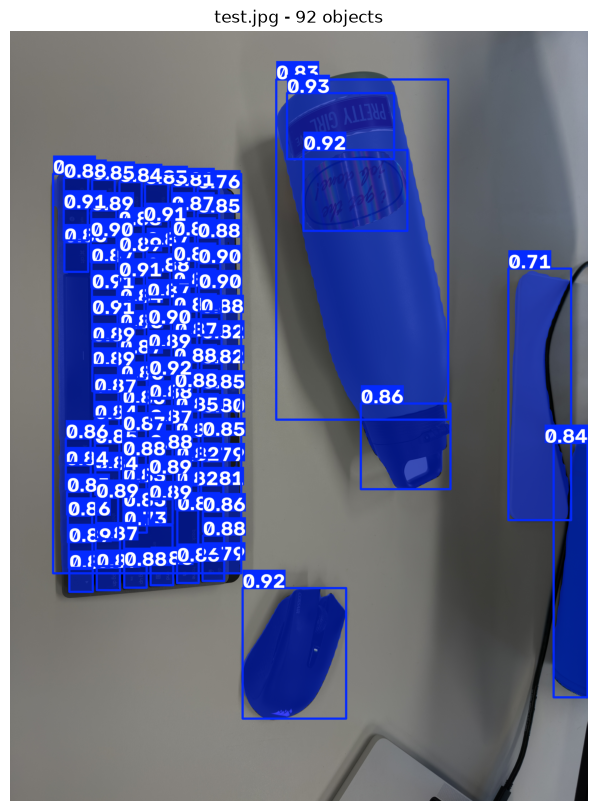


image 1/1 /Users/anagoncalves/HES/Mushrooms-recognition/models_evaluation/data/fastSAM/istockphoto-842160124-612x612.jpg: 704x1024 24 objects, 106.8ms
Speed: 3.3ms preprocess, 106.8ms inference, 7.2ms postprocess per image at shape (1, 3, 704, 1024)


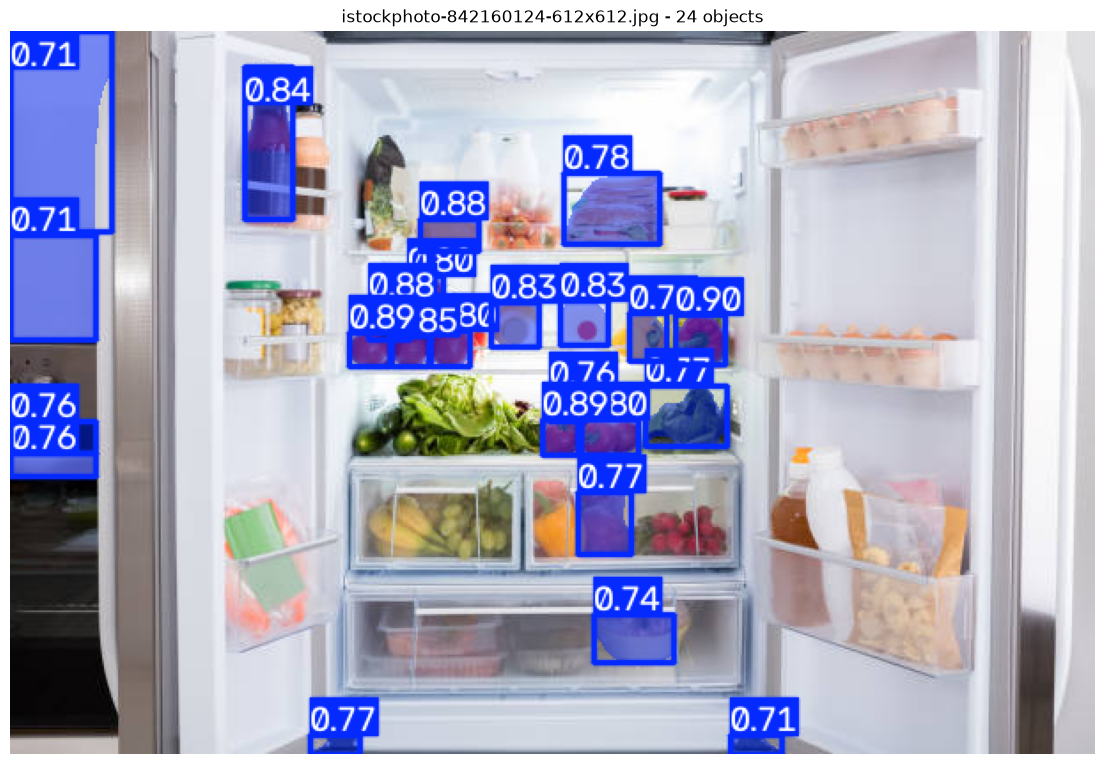


image 1/1 /Users/anagoncalves/HES/Mushrooms-recognition/models_evaluation/data/fastSAM/objects.jpg: 576x1024 51 objects, 73.6ms
Speed: 1.0ms preprocess, 73.6ms inference, 10.5ms postprocess per image at shape (1, 3, 576, 1024)


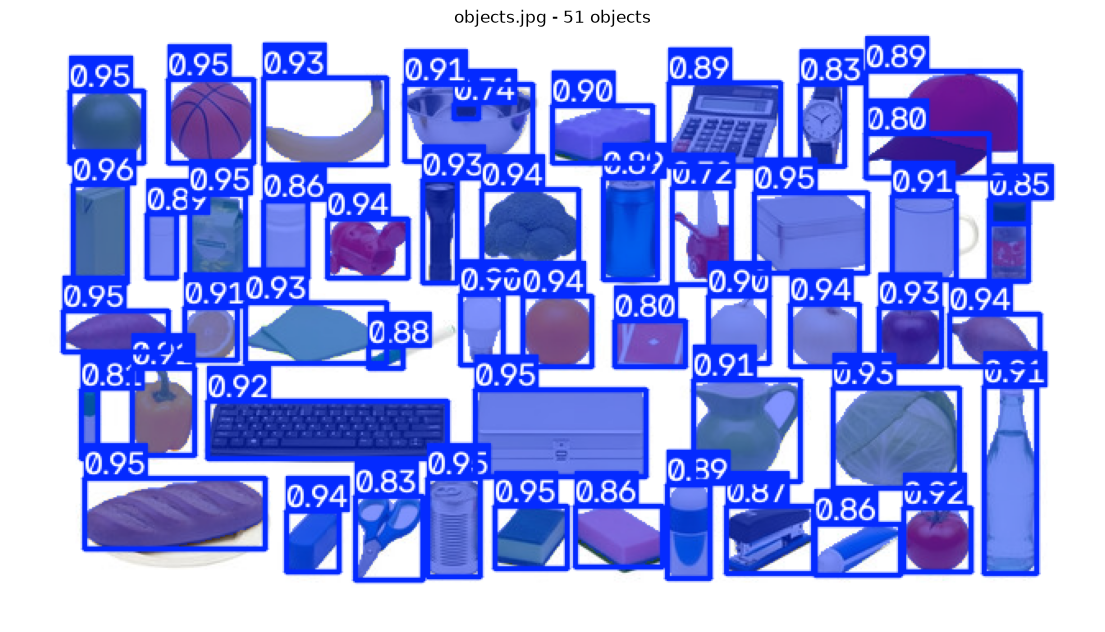


image 1/1 /Users/anagoncalves/HES/Mushrooms-recognition/models_evaluation/data/fastSAM/food1.jpeg: 704x1024 40 objects, 80.2ms
Speed: 1.2ms preprocess, 80.2ms inference, 9.7ms postprocess per image at shape (1, 3, 704, 1024)


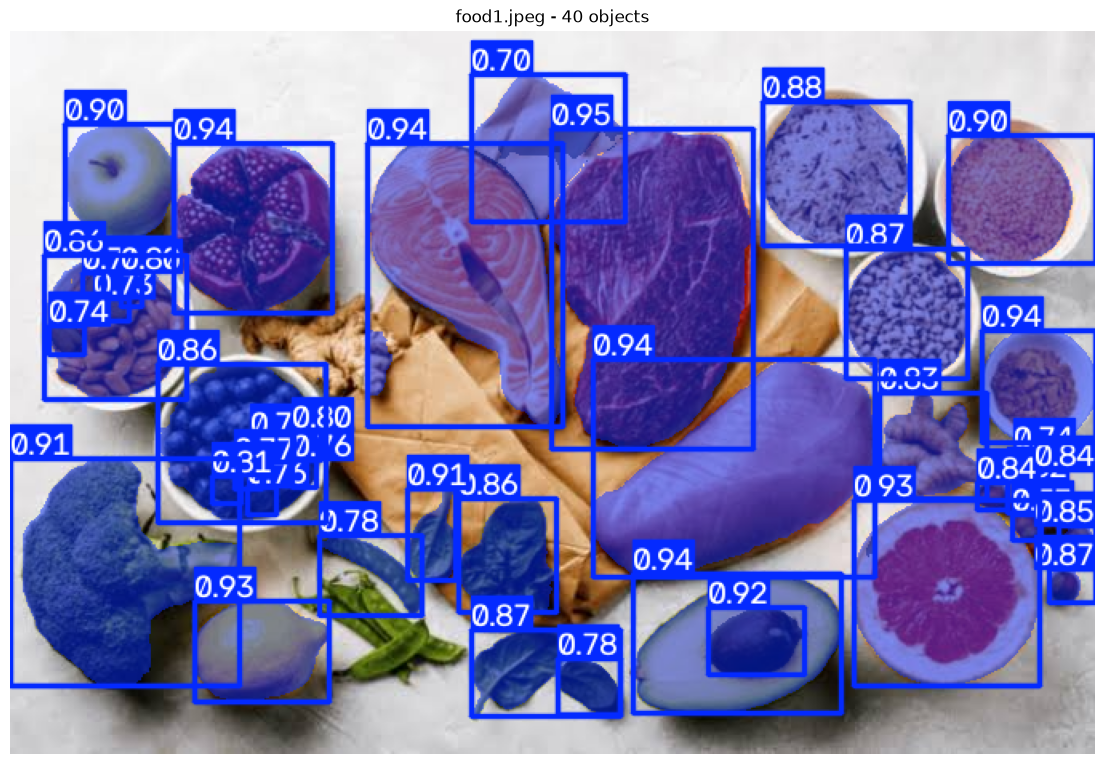

In [5]:
for image_path in Path(img_folder).iterdir():
    if image_path.suffix.lower() not in {".jpg", ".jpeg", ".png"}:
        continue

    # Detect all objects
    # conf is to say how confident we have to be so that object is detected
    # iou is to say how much overlap we allow between detected objects
    results = model(
        str(image_path),
        device="cpu",
        retina_masks=True,
        imgsz=1024,
        conf=0.7,
        iou=0.4,
    )

    # Visualize the results
    annotated_image = results[0].plot(
        boxes=True,
        masks=True,
        labels=False,
    )

    plt.figure(figsize=(14, 10))
    plt.imshow(annotated_image[..., ::-1])
    plt.title(f"{image_path.name} - {len(results[0].boxes)} objects")
    plt.axis("off")
    plt.show()

As we can see, when ingredients are in a fridge, it is much harder to segment them. One of the constraints of using this model will be to ask users to take pictures of the ingredients outside of the fridge and lay them in a surface. Because those are the best results that we can get with this model. 

With the same parameters, model X performs better but is slightly slower than model S. We will measure how different the results are and if it is worth using model X instead of model S.


image 1/1 /Users/anagoncalves/HES/Mushrooms-recognition/models_evaluation/data/fastSAM/food1.jpeg: 704x1024 33 objects, 444.5ms
Speed: 2.0ms preprocess, 444.5ms inference, 13.3ms postprocess per image at shape (1, 3, 704, 1024)
Time taken: 0.56 seconds for model X


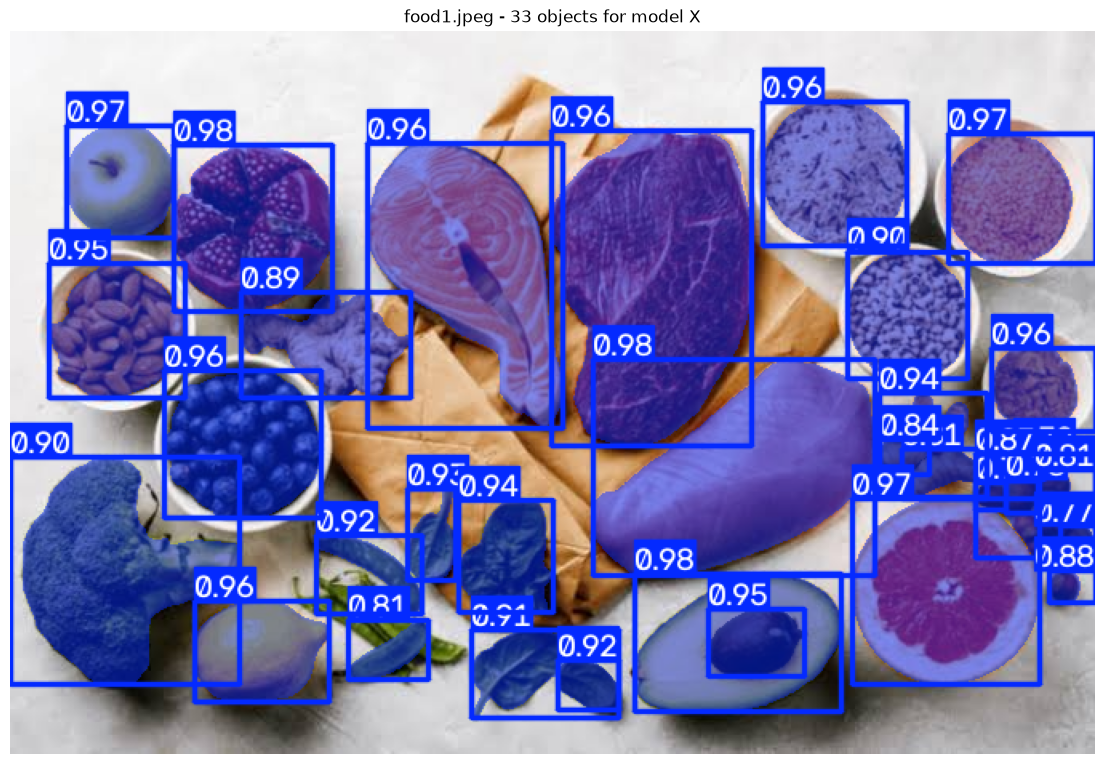


image 1/1 /Users/anagoncalves/HES/Mushrooms-recognition/models_evaluation/data/fastSAM/food1.jpeg: 704x1024 40 objects, 98.9ms
Speed: 1.4ms preprocess, 98.9ms inference, 12.4ms postprocess per image at shape (1, 3, 704, 1024)
Time taken: 0.15 seconds for model S


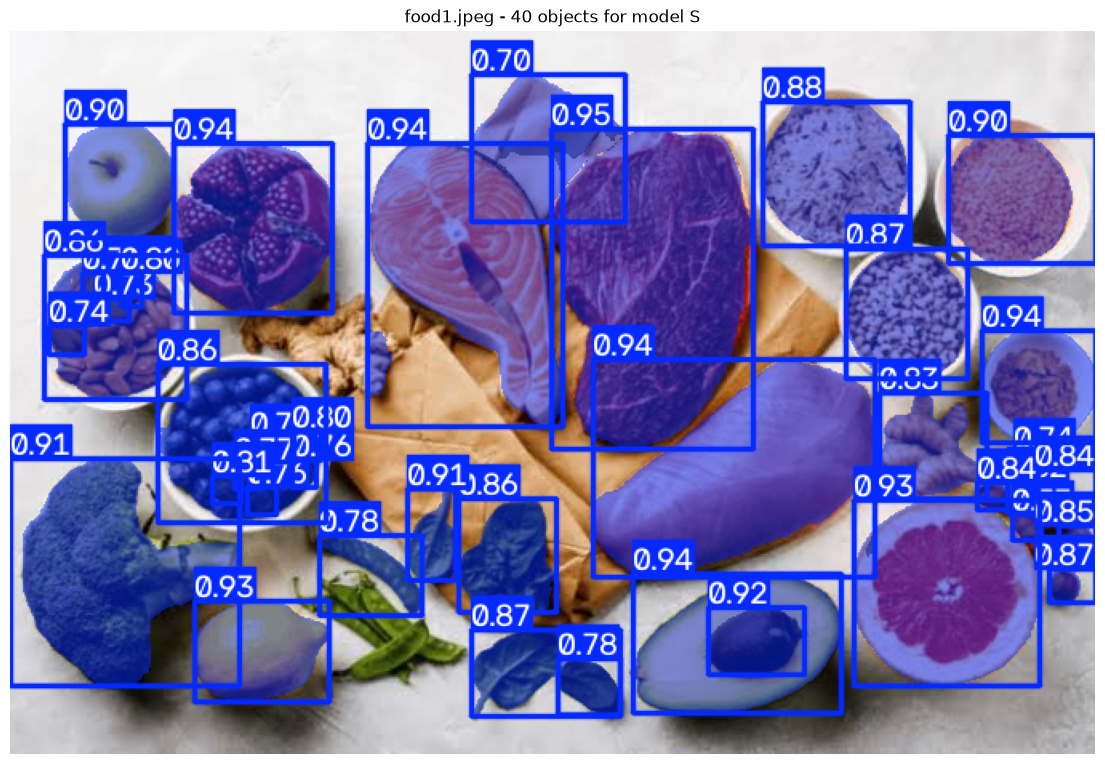

In [9]:
# whole pipeline for one image and track time, without bounding boxes
debugging = True

# model X
start_time = time.time()

# Perform the entire pipeline for one image
results = FastSAM(model_x)(
    source="data/fastSAM/food1.jpeg",
    retina_masks=True,
    imgsz=1024,
    conf=0.7,
    iou=0.5,
)

end_time = time.time()
print(f"Time taken: {end_time - start_time:.2f} seconds for model X")

# plot bouding boxes outside of time tracking
if debugging:
    # Visualize the results
    annotated_image = results[0].plot(
        boxes=True,
        masks=True,
        labels=False,
    )

    plt.figure(figsize=(14, 10))
    plt.imshow(annotated_image[..., ::-1])
    plt.title(f"{image_path.name} - {len(results[0].boxes)} objects for model X")
    plt.axis("off")
    plt.show()


# now for model S
start_time = time.time()

# Perform the entire pipeline for one image
results = FastSAM(model_s)(
    source="data/fastSAM/food1.jpeg",
    retina_masks=True,
    imgsz=1024,
    conf=0.7,
    iou=0.5,
)

end_time = time.time()
print(f"Time taken: {end_time - start_time:.2f} seconds for model S")

if debugging:
    # Visualize the results
    annotated_image = results[0].plot(
        boxes=True,
        masks=True,
        labels=False,
    )

    plt.figure(figsize=(14, 10))
    plt.imshow(annotated_image[..., ::-1])
    plt.title(f"{image_path.name} - {len(results[0].boxes)} objects for model S")
    plt.axis("off")
    plt.show()

Model S is 3,3 times faster than model X, but model X is more accurate and performs better when ingredients are close together. 
Model X took 0,5 seconds to segment an image, while model S took 0,15 seconds.

Things that will need to be done in order to use this model:
- Ask users to take pictures of the ingredients outside of the fridge and lay them in a surface.
- If one mask is inside another mask, remove the inner mask (example: avocado seed)
- Make sure all images have the same size
- Crop the images according to their masks